# Decay of an unstable state

Langevin equation: $\boxed{\dot{x} = ax - bx^3 + \sqrt{D}\xi(t)}$

Deterministic solution: $\boxed{x(t) = \displaystyle\frac{x_0}{\sqrt{e^{-2at}(1-A) + A}}, \quad A = \frac{x_0^2b}{a}}$

Probability potential: $\boxed{V(x) = -ax^2 + \frac{1}{2}bx^4}$

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import os

a = 4
b = 1
D = 0.01

directorio = os.getcwd()
data = np.loadtxt(os.path.join(directorio, "Trajectories.txt"))

time = np.linspace(0, 4, 40)
x = data[:, :-4]
x_mean = data[:, -4]
x2_mean = data[:, -3]
x4_mean = data[:, -2]
x2_variance = data[:, -1]
N = x.shape[1]

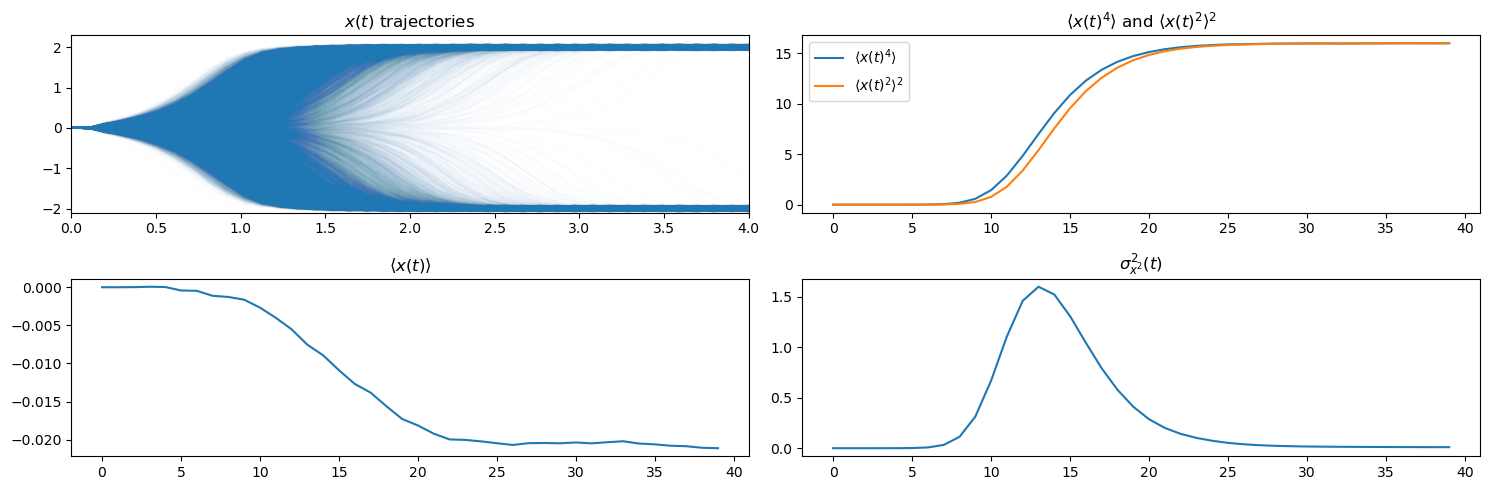

In [9]:
# Gráfica de las trayectorias
fig, ax = plt.subplots(ncols=2, nrows=2, figsize=(15, 5))

vertices = [np.column_stack((time, x[:, i])) for i in range(N)]

lc = LineCollection(vertices, alpha=0.01)
ax[0, 0].add_collection(lc)
ax[0, 0].set(title=r'$x(t)$ trajectories', xlim=(0, 4), ylim=(min([0, x.min()]), max([2.3, x.max()])))
ax[0, 1].plot(x4_mean, label=r'$\langle x(t)^4\rangle$')
ax[0, 1].plot(x2_mean**2, label=r'$\langle x(t)^2\rangle^2$')
ax[0, 1].set(title=r'$\langle x(t)^4\rangle$ and $\langle x(t)^2\rangle^2$')
ax[1, 0].plot(x_mean)
ax[1, 0].set(title=r'$\langle x(t)\rangle$')
ax[1, 1].plot(x2_variance)
ax[1, 1].set(title=r'$\sigma^2_{x^2}(t)$')

ax[0, 1].legend()
plt.tight_layout()
plt.show()

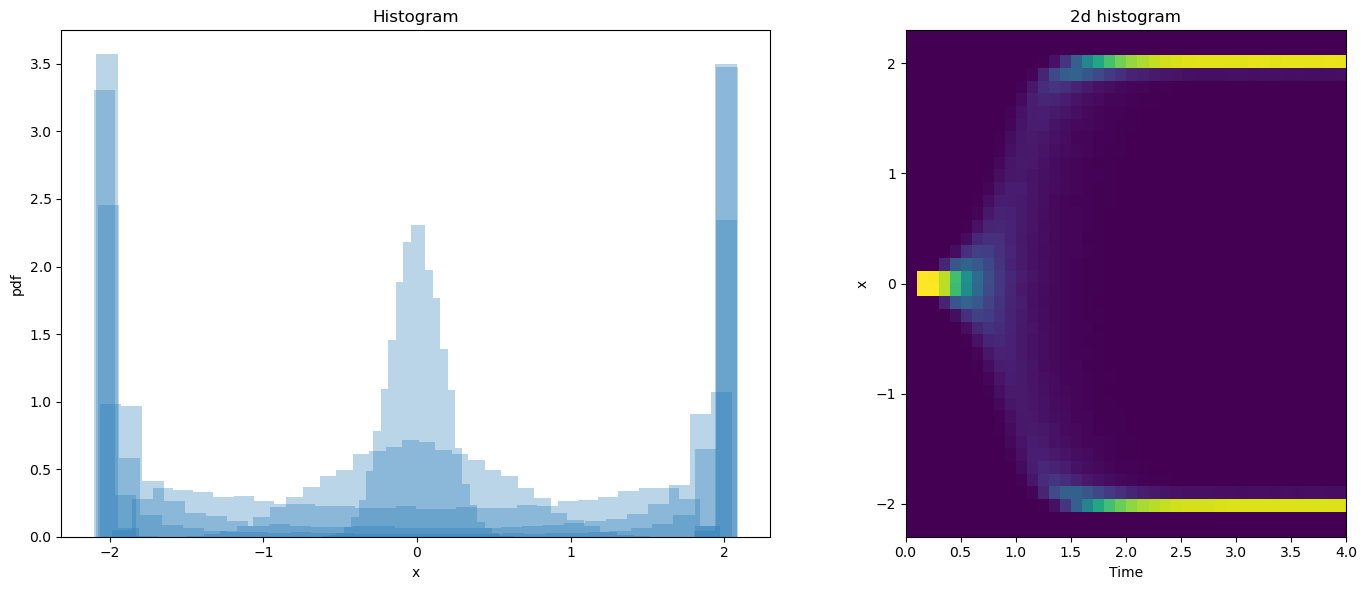

In [10]:
# Histogramas de la distribución
fig, ax = plt.subplots(ncols=2, figsize=(15, 6))
for t in [5, 8, 11, 14, 17, 29, 39]:
    ax[0].hist(x[t], bins = 30, alpha = 0.3, density=True, color='C0')

ax[0].set(title='Histogram', xlabel='x', ylabel='pdf')
n_bins = 40
n = np.zeros((time.shape[0], n_bins))

for i in range(1, time.shape[0]):
    n[i], _ = np.histogram(a=x[i], bins=n_bins, density=True, range=[-2.3, 2.3])

ax[1].imshow(n.T, extent=(0, 4, -2.3, 2.3))
ax[1].set(title='2d histogram', xlabel='Time', ylabel='x')

fig.tight_layout()
plt.show()

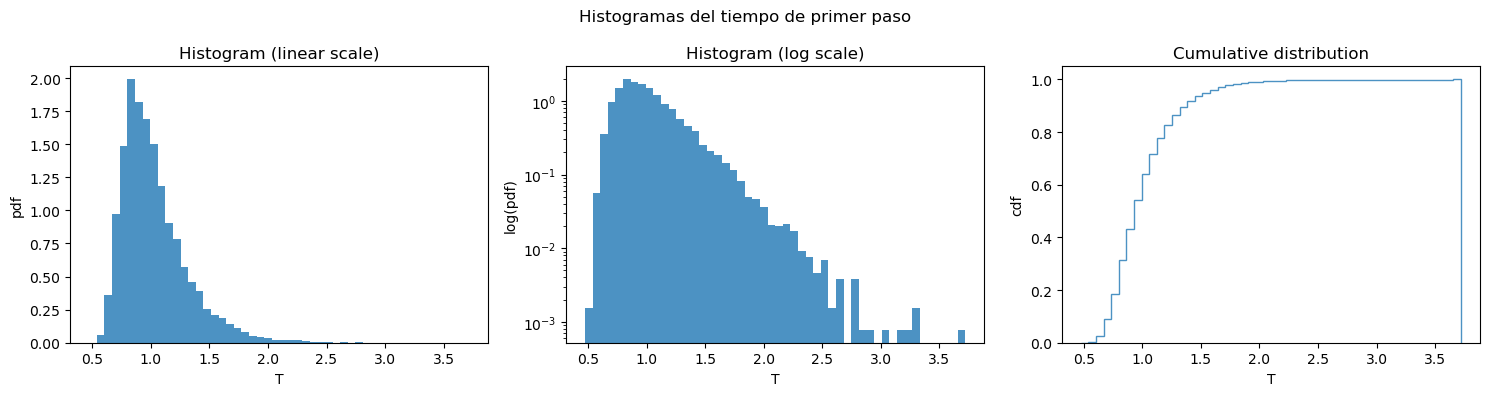

In [14]:
# First passage

dt = 0.1
R = 0.5
abs_x = np.abs(x)
indices = np.argmax(abs_x - R > 0, axis=0)
pre_R = np.zeros(N)
post_R = np.zeros(N)
for i, index in enumerate(indices):
    pre_R[i] = abs_x[index-1, i]
    post_R[i] = abs_x[index, i]

inter_indices = indices + (R - pre_R) / (post_R - pre_R)
first_passage_time = dt * inter_indices

fig, ax = plt.subplots(ncols=3, figsize=(15, 4))
fig.suptitle('Histogramas del tiempo de primer paso')
ax[0].hist(first_passage_time, bins=50, density=True, alpha=0.8)
ax[0].set(xlabel='T', ylabel='pdf', title='Histogram (linear scale)')
ax[1].hist(first_passage_time, bins=50, density=True, alpha=0.8, log=True)
ax[1].set(xlabel='T', ylabel='log(pdf)', title='Histogram (log scale)')
ax[2].hist(first_passage_time, bins=50, density=True, cumulative=True, alpha=0.8, histtype='step')
ax[2].set(xlabel='T', ylabel='cdf', title='Cumulative distribution')

fig.tight_layout()
plt.show()

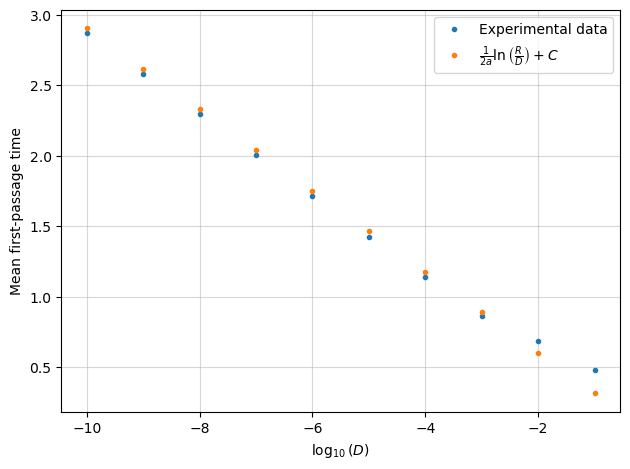

In [44]:
# Mean first-passage time

mfpt_data = np.loadtxt(os.path.join(directorio, "Mean_passage_time.txt"))

D = mfpt_data[:, 0]
mfpt = mfpt_data[:, 1]

a0, a1 = np.polyfit(np.log10(D), mfpt, 1)
y_pred = 1/(2 * a) * np.log(R/D) + a1

plt.plot(np.log10(D), mfpt, 'C0.', label='Experimental data')
plt.plot(np.log10(D), y_pred, 'C1.', label=r"$\frac{1}{2a}\ln\left(\frac{R}{D}\right)+C$")
plt.xlabel(r"$\log_{10}(D)$")
plt.ylabel(r"Mean first-passage time")
plt.legend()
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()